# Experiment 5 — Tactical deconfliction between UAVs

The U2U scenario from Experiment 4 is repeated with strategic deconfliction disabled. Tracking is active in both cases, and the tactical algorithms are enabled only in the second case.

In [1]:
from pathlib import Path

from IPython.display import Image, Markdown, display

from musas.airspace import Airspace
from musas.algorithms import (
    FirstOrderDynamics,
    FlightPlanAwareTracking,
    HybridGeometricManeuver,
    MinimumSeparationTacticalConflictPrediction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    plot_dataset,
)
from musas.simulation.metrics import calculate_metrics

OUTPUT_DIRECTORY = Path("outputs") / "output_5"
FIGURE_DIRECTORY = Path("figs") / "figs_5"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)

## Parameters

| Component | Parameter | Value | Note |
|---|---|---:|---|
| Experiment | Cases | Without TD; With TD | Used |
| Experiment | Simulation end | 45.0 s | Used |
| Flight plans | Altitude | 100.0 m | Used |
| Flight plans | Start / arrival time | 2.0 / 22.0 s | Used |
| Flight plans | Nominal intersection time | 12.0 s | Used |
| Flight plans | Priority | 0 for both UAVs | Default; tie resolved by FCFS order |
| UAV A | Route | $(-100,0)$ to $(100,0)$ m | Used |
| UAV B | Route | $(0,-100)$ to $(0,100)$ m | Used |
| Tracking | Algorithm | FlightPlanAwareTracking | Used in both cases |
| Tracking | Report interval | 0.25 s | Used |
| Tracking | History window | 6 reports | Default |
| Tracking | Prediction horizon | 24 steps | Used |
| Tracking | Prediction step | 0.25 s | Used; total horizon = 6.0 s |
| Tactical CP | Algorithm | MinimumSeparationTacticalConflictPrediction | With-TD case only |
| Tactical CP | Minimum separation | 30.0 m | Used |
| Tactical CP | Maximum time difference | 0.25 s | Used |
| Tactical deconfliction | Algorithm | HybridGeometricManeuver | With-TD case only |
| Tactical deconfliction | Vertical offset | 60.0 m | Used |
| Tactical deconfliction | Airspace clearance | 15.0 m | Used; inactive for U2U |
| Tactical deconfliction | Maneuver / recovery duration | 4.0 / 8.0 s | Used / default |
| Tactical deconfliction | Minimum / maximum speed | 1.0 / 15.0 m/s | Default / used |
| Tactical deconfliction | Cooldown | 2.0 s | Used |
| Tactical deconfliction | Maximum escape distance | 500.0 m | Default; inactive for U2U |
| Simulation | Strategic deconfliction | Disabled | Both strategic algorithms are `None` |
| Simulation | Tactical-assessment interval | 0.25 s | Used |
| Simulation | Network delay | 0.0 s | Default |
| Simulation | Flight-update interval | 0.1 s | Default |
| Simulation | Trajectory-record interval | 0.2 s | Default |
| Simulation | Collision distance | 1.0 m | Default |
| Simulation | Processing times | 0.0 s | Defaults |
| UAVs | Submission time | 0.0 s | Default |
| UAVs | Registration / tie-break order | UAV A, then UAV B | Used |
| UAVs | Waypoint acceptance radius | 1.0 m | Default |
| Dynamics | Velocity time constant / max. acceleration | 0.0 s / 100.0 m/s² | Used |
| Guidance | Minimum / maximum speed | 0.0 / 15.0 m/s | Default / used |
| Sensors | Sensor model | PerfectSensor | UAV default |
| Airspace | Obstacles, geofences and wind zones | None | Used |
| Dataset | Flush interval / keep history | 10.0 s / True | Defaults |
| Dataset | Overwrite existing file | True | Used |
| Network events | Message types logged | None | Used |
| Metrics | Minimum separation / collision distance | 30.0 / 1.0 m | Used |
| Visualization | Before-update snapshot | 2.75 s | Last tracks before update at 3.0 s |
| Visualization | Conflict-time snapshot | 12.0 s | Used |
| Visualization | Views | XY, YZ and 3D | Used |
| Visualization | Frame step | 0.25 s | Used |
| Visualization | Figure size / static DPI | $(8.0,5.5)$ in / 300 | Defaults |
| Visualization | Animation FPS / DPI | 10 / 120 | Used / default |
| Visualization | Plans, trajectories, tracks, positions, legend, grid | Shown | Used/default |
| Visualization | Reports and airspace layers | Hidden | Used |

In [2]:
SIMULATION_END = 45.0
BEFORE_UPDATE_TIME = 2.75
CONFLICT_TIME = 12.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 1.0

def create_flight_plans():
    return {
        "UAV A": FlightPlan([
            Waypoint(-100.0, 0.0, 100.0, 2.0),
            Waypoint(100.0, 0.0, 100.0, 22.0),
        ]),
        "UAV B": FlightPlan([
            Waypoint(0.0, -100.0, 100.0, 2.0),
            Waypoint(0.0, 100.0, 100.0, 22.0),
        ]),
    }

## Run both cases

Tracking is active in both cases. With equal priorities, only UAV B is selected for the tactical vertical maneuver.

In [3]:
def run_case(case_name, use_td):
    dataset_path = OUTPUT_DIRECTORY / f"{case_name}.sqlite"
    tracking = FlightPlanAwareTracking()

    tactical_predictor = None
    tactical_deconfliction = None
    if use_td:
        tactical_predictor = MinimumSeparationTacticalConflictPrediction(
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            maximum_time_difference=0.25,
        )
        tactical_deconfliction = HybridGeometricManeuver(
            conflict_prediction_algorithm=tactical_predictor,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            vertical_offset=60.0,
            airspace_clearance=15.0,
            maneuver_duration=4.0,
            recovery_duration=8.0,
            minimum_speed=1.0,
            maximum_speed=15.0,
            cooldown=2.0,
            maximum_escape_distance=500.0,
        )

    simulation = Simulation(
        airspace=Airspace(),
        strategic_conflict_prediction_algorithm=None,
        strategic_deconfliction_algorithm=None,
        tracking_algorithm=tracking,
        tactical_conflict_prediction_algorithm=tactical_predictor,
        tactical_deconfliction_algorithm=tactical_deconfliction,
        report_interval=0.25,
        history_window=6,
        prediction_horizon=24,
        prediction_step=0.25,
        tactical_assessment_interval=0.25,
        message_types_to_log=(),
        dataset_path=dataset_path,
        dataset_metadata={"experiment": 5, "case": case_name},
        overwrite_dataset=True,
    )
    for uav_name, flight_plan in create_flight_plans().items():
        simulation.add_uav(
            name=uav_name,
            flight_plan=flight_plan,
            dynamics_algorithm=FirstOrderDynamics(
                max_acceleration=100.0,
                velocity_time_constant=0.0,
            ),
            guidance_algorithm=WaypointGuidance(
                min_speed=0.0,
                max_speed=15.0,
            ),
        )
    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path

dataset_paths = {
    "Without TD": run_case("without_td", use_td=False),
    "With TD": run_case("with_td", use_td=True),
}
dataset_paths

{'Without TD': PosixPath('outputs/output_5/without_td.sqlite'),
 'With TD': PosixPath('outputs/output_5/with_td.sqlite')}

## Results

In [4]:
table = [
    "| Case | Final status | Tactical conflicts | Interventions | "
    "Losses of separation | Collisions | Minimum separation | UAV B updates |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            collision_distance=COLLISION_DISTANCE,
        )
        statuses = ", ".join(
            f"{uav.name}: {uav.final_status}"
            for uav in dataset.get_uavs()
        )
    separation = metrics["minimum_pairwise_separation"]
    separation_text = "N/A" if separation is None else f"{separation:.2f}"
    table.append(
        f"| {case_name} | {statuses} | {metrics['detected_tactical_conflicts']} | "
        f"{metrics['tactical_interventions']} | {metrics['loss_of_separation_events']} | "
        f"{metrics['collision_events']} | {separation_text} | "
        f"{metrics['per_uav']['UAV B']['updates']} |"
    )
display(Markdown("\n".join(table)))

| Case | Final status | Tactical conflicts | Interventions | Losses of separation | Collisions | Minimum separation | UAV B updates |
|---|---|---:|---:|---:|---:|---:|---:|
| Without TD | UAV A: COLLIDED, UAV B: COLLIDED | 0 | 0 | 1 | 1 | 0.00 | 0 |
| With TD | UAV A: COMPLETED, UAV B: COMPLETED | 4 | 1 | 0 | 0 | 58.70 | 1 |

## Track snapshots and animations

The XY snapshot before the update shows the predicted U2U conflict. At the nominal conflict time, the YZ view exposes the vertical maneuver applied to UAV B.

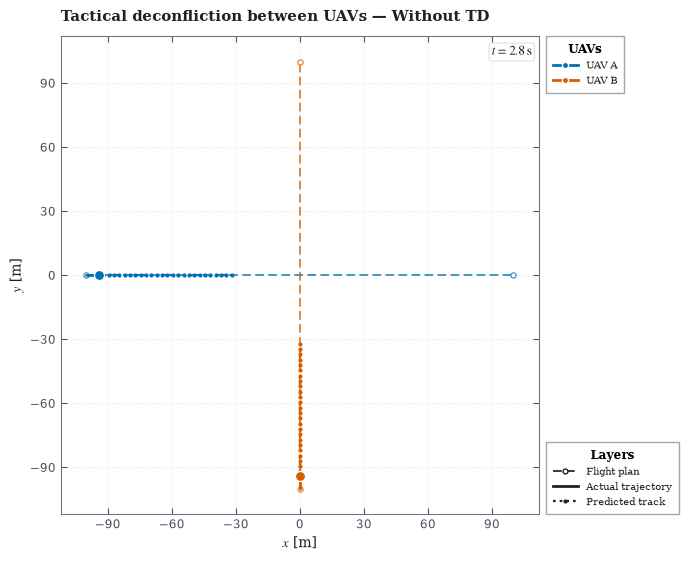

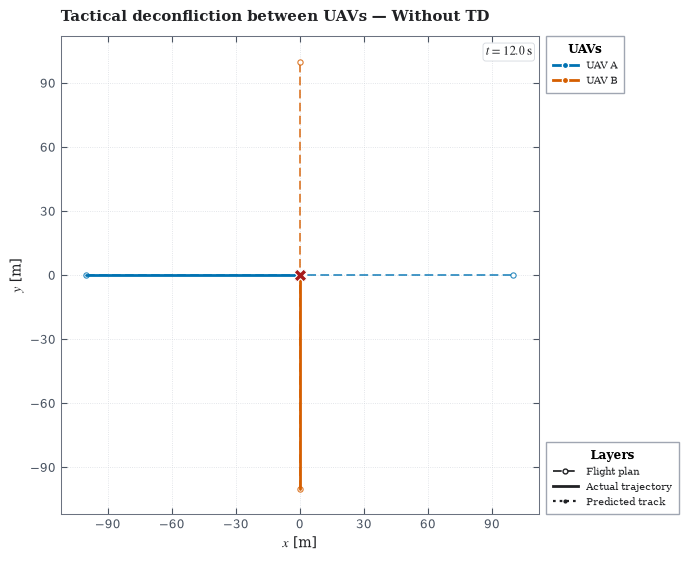

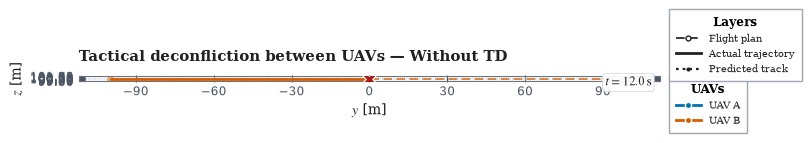

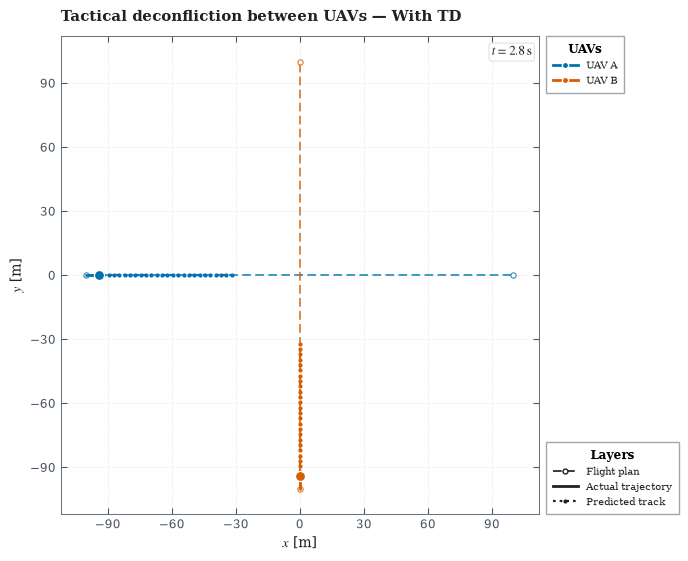

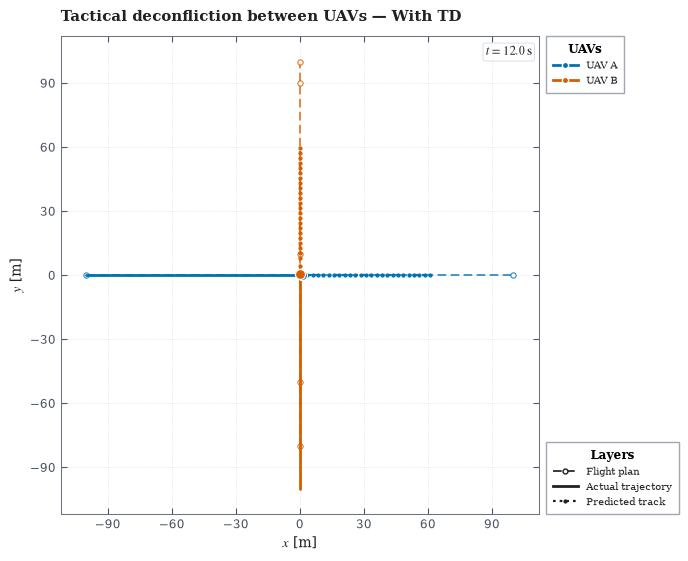

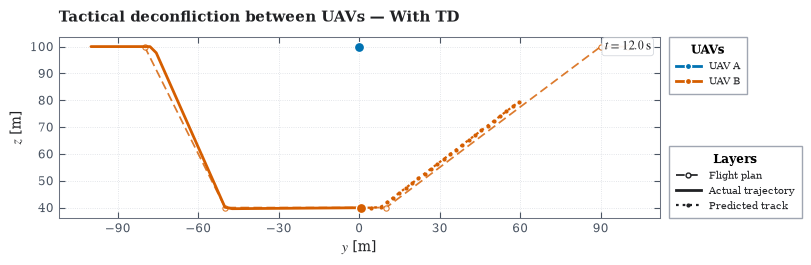

Figures: /Users/caiobianchi/Desktop/ITA/TG/TG_codigo/experiments/figs/figs_5


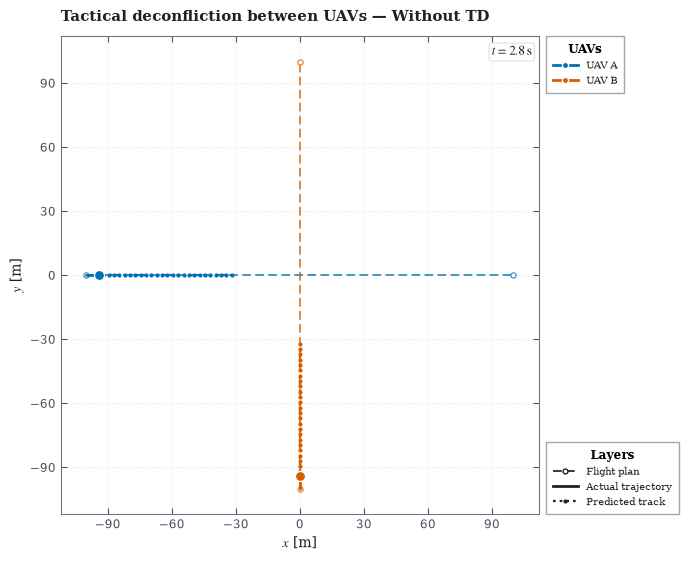

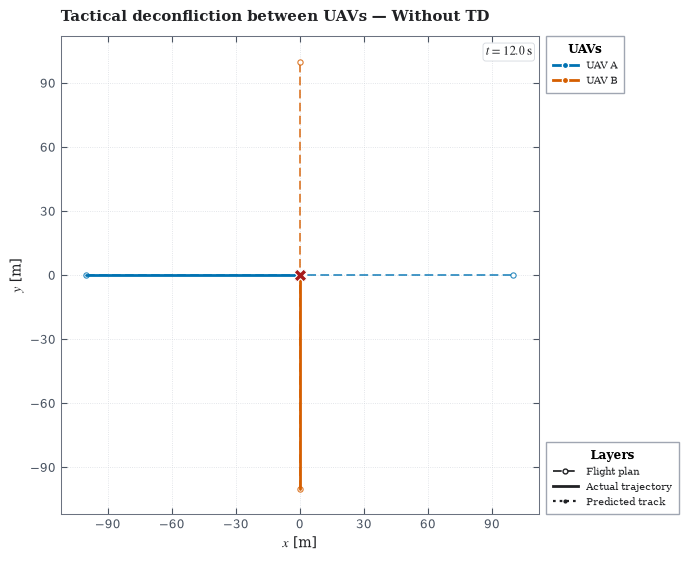

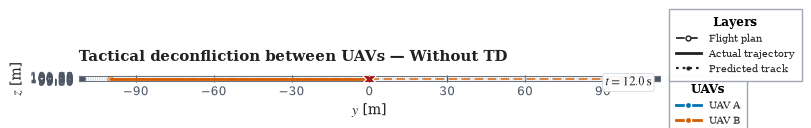

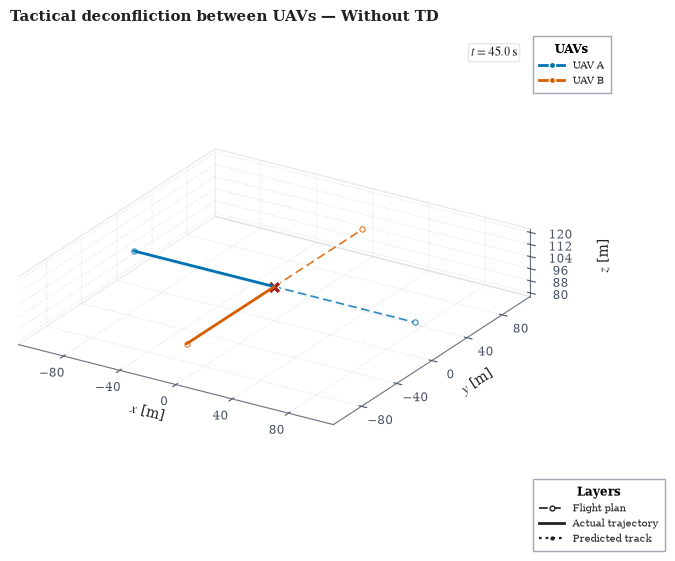

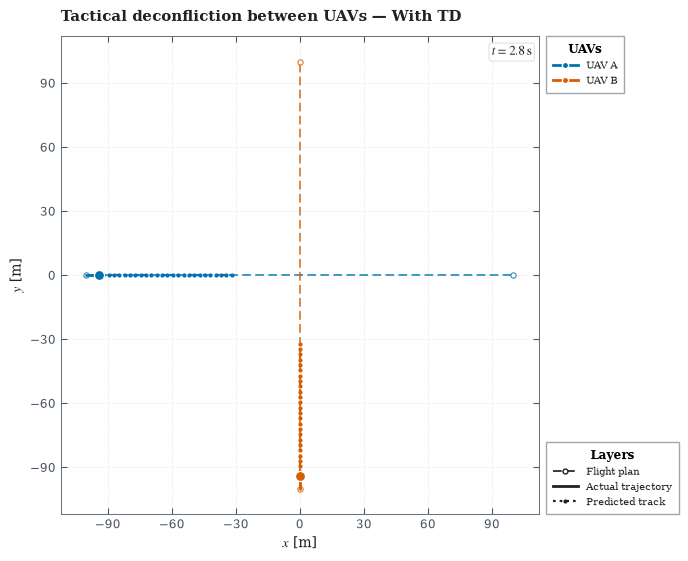

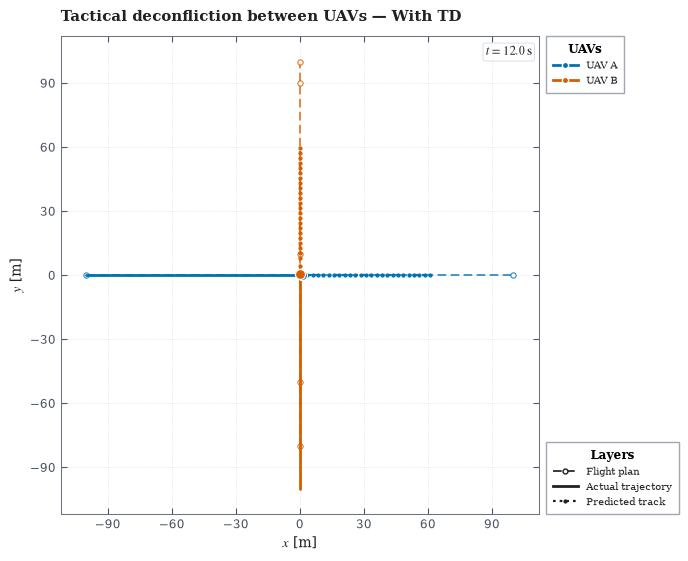

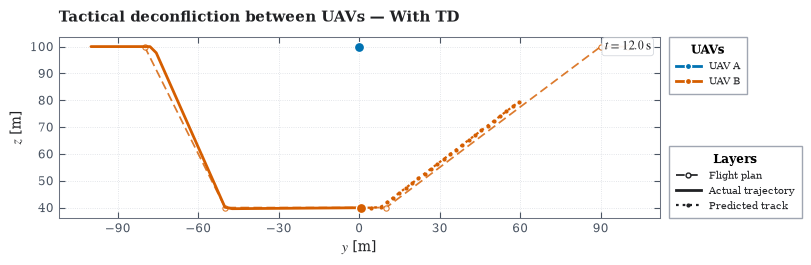

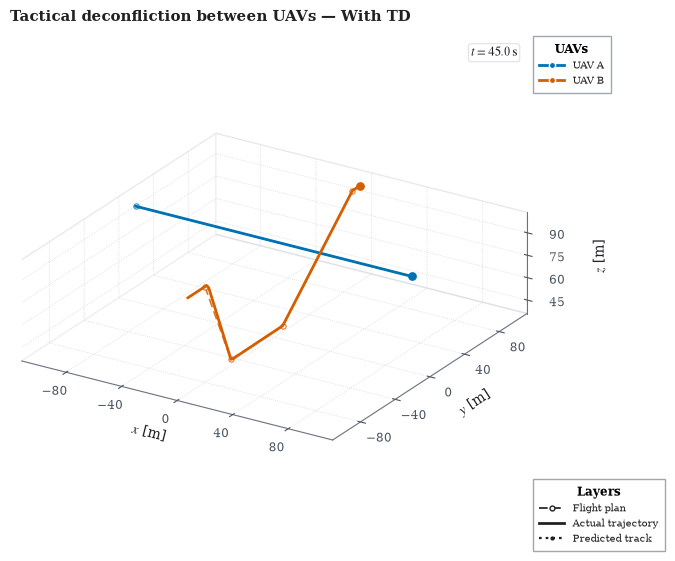

In [5]:
def visualization_config(case_name, view):
    return VisualizationConfig(
        uav_names=("UAV A", "UAV B"),
        view=view,
        show_real_trajectories=True,
        show_current_positions=True,
        show_tracks=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=False,
        frame_step=0.25,
        title=f"Tactical deconfliction between UAVs — {case_name}",
        spatial_unit="m",
    )

animation_paths = {}
for case_name, dataset_path in dataset_paths.items():
    file_label = case_name.lower().replace(" ", "_")
    before_figure = plot_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name, "xy"),
        timestamp=BEFORE_UPDATE_TIME,
        output_path=FIGURE_DIRECTORY / f"{file_label}_before_update_xy.png",
    )
    display(before_figure)
    conflict_xy_figure = plot_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name, "xy"),
        timestamp=CONFLICT_TIME,
        output_path=FIGURE_DIRECTORY / f"{file_label}_conflict_time_xy.png",
    )
    display(conflict_xy_figure)
    conflict_yz_figure = plot_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name, "yz"),
        timestamp=CONFLICT_TIME,
        output_path=FIGURE_DIRECTORY / f"{file_label}_conflict_time_yz.png",
    )
    display(conflict_yz_figure)
    animation_path = FIGURE_DIRECTORY / f"{file_label}_3d.gif"
    animate_dataset(
        dataset_path=dataset_path,
        config=visualization_config(case_name, "3d"),
        output_path=animation_path,
        fps=10.0,
    )
    animation_paths[case_name] = animation_path

print("Figures:", FIGURE_DIRECTORY.resolve())

### Without TD

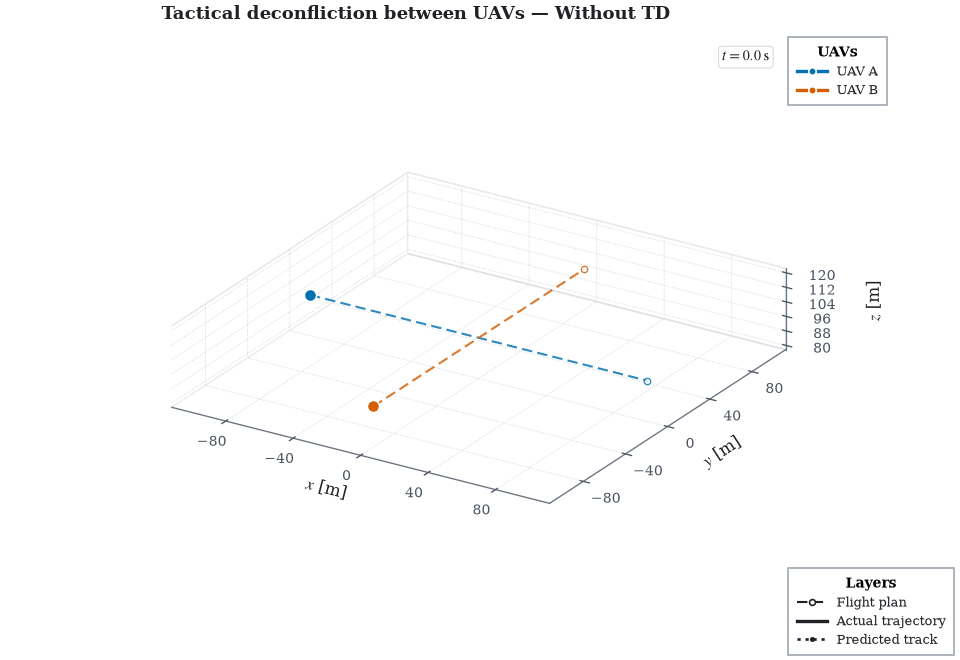

### With TD

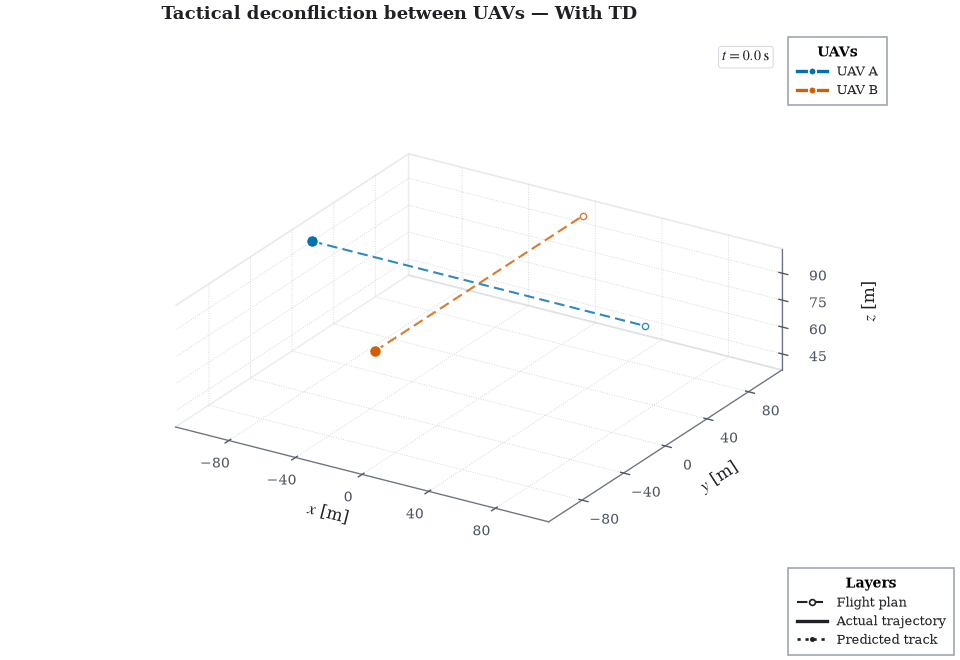

In [6]:
for case_name, animation_path in animation_paths.items():
    display(Markdown(f"### {case_name}"))
    display(Image(filename=animation_path))